# E-commerce Product Analytics

## О проекте

В этом проекте я анализирую продажи и поведение клиентов
e-commerce marketplace на реальном наборе данных Olist.

Цель анализа — оценить ключевые бизнес- и продуктовые метрики,
исследовать повторные покупки и retention, определить наиболее
значимые товарные категории и проверить, как качество доставки
связано с пользовательскими оценками.

### Основные вопросы

- Как меняются количество заказов и выручка?
- Каков средний чек?
- Какая доля клиентов совершает повторные покупки?
- Как меняется retention по когортам?
- Какие категории формируют наибольшую выручку?
- Насколько часто заказы доставляются с опозданием?
- Связаны ли задержки доставки с пользовательскими оценками?

### Стек

SQL · SQLite · Python · pandas · matplotlib

In [2]:
import pandas as pd
import sqlite3

## 1. Подготовка данных

Для анализа используются несколько связанных таблиц Olist:
данные о клиентах, заказах, товарах, платежах и отзывах.

CSV-файлы загружаются в pandas, после чего переносятся
в локальную SQLite-базу. Основная часть анализа выполняется с помощью SQL.

In [3]:
customers = pd.read_csv("olist_customers_dataset.csv")
orders = pd.read_csv("olist_orders_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
payments = pd.read_csv("olist_order_payments_dataset.csv")
reviews = pd.read_csv("olist_order_reviews_dataset.csv")

In [4]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [5]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:
tables = {
    "customers": customers,
    "orders": orders,
    "order_items": order_items,
    "products": products,
    "payments": payments,
    "reviews": reviews
}

for name, df in tables.items():
    print(name, df.shape)

customers (99441, 5)
orders (99441, 8)
order_items (112650, 7)
products (32951, 9)
payments (103886, 5)
reviews (99224, 7)


In [7]:
for name, df in tables.items():
    print("\n", name.upper())
    print(df.columns.tolist())


 CUSTOMERS
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

 ORDERS
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

 ORDER_ITEMS
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

 PRODUCTS
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

 PAYMENTS
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

 REVIEWS
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']


### Создание SQL-базы

Для выполнения SQL-запросов создаю локальную SQLite-базу
и сохраняю в неё исходные таблицы.

In [8]:
conn = sqlite3.connect("ecommerce.db")

In [9]:
customers.to_sql("customers", conn, if_exists="replace", index=False)
orders.to_sql("orders", conn, if_exists="replace", index=False)
order_items.to_sql("order_items", conn, if_exists="replace", index=False)
products.to_sql("products", conn, if_exists="replace", index=False)
payments.to_sql("payments", conn, if_exists="replace", index=False)
reviews.to_sql("reviews", conn, if_exists="replace", index=False)

99224

## 2. Первичное исследование данных

Сначала проверяю объём данных, количество заказов и уникальных клиентов,
а также определяю временной период, который покрывает датасет.

In [10]:
query = """
SELECT *
FROM orders
LIMIT 10;
"""

pd.read_sql(query, conn)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,None,None,2017-05-09 00:00:00
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00


In [11]:
query = """
SELECT COUNT(DISTINCT order_id) AS total_orders
FROM orders;
"""

pd.read_sql(query, conn)

,total_orders
0,99441


In [12]:
query = """
SELECT COUNT(DISTINCT customer_unique_id) AS total_customers
FROM customers;
"""

pd.read_sql(query, conn)

,total_customers
0,96096


In [13]:
query = """
SELECT
    MIN(order_purchase_timestamp) AS first_order,
    MAX(order_purchase_timestamp) AS last_order
FROM orders;
"""

pd.read_sql(query, conn)

,first_order,last_order
0,2016-09-04 21:15:19,2018-10-17 17:30:18


**Промежуточный вывод.**

Датасет содержит около 99 тыс. заказов и 96 тыс. уникальных клиентов
за период с сентября 2016 по октябрь 2018 года.

Количество заказов немного превышает число клиентов, поэтому далее отдельно
проверяется доля пользователей, совершающих повторные покупки.

In [14]:
query = """
SELECT
    order_status,
    COUNT(*) AS orders_count
FROM orders
GROUP BY order_status
ORDER BY orders_count DESC;
"""

pd.read_sql(query, conn)

,order_status,orders_count
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


## 3. Проверка качества данных

Перед расчётом метрик проверяю статусы заказов и наличие пропусков
в ключевых полях.

Для финансовых и продуктовых показателей далее используются доставленные
заказы, чтобы отменённые и незавершённые заказы не искажали результаты.

In [15]:
query = """
SELECT
    COUNT(*) AS total_rows,
    SUM(CASE WHEN order_id IS NULL THEN 1 ELSE 0 END) AS missing_order_id,
    SUM(CASE WHEN customer_id IS NULL THEN 1 ELSE 0 END) AS missing_customer_id,
    SUM(CASE WHEN order_purchase_timestamp IS NULL THEN 1 ELSE 0 END) AS missing_purchase_date
FROM orders;
"""

pd.read_sql(query, conn)

,total_rows,missing_order_id,missing_customer_id,missing_purchase_date
0,99441,0,0,0


## 4. Основные бизнес-метрики

Рассчитываю выручку и среднюю стоимость заказа (AOV)
для успешно доставленных заказов.

In [18]:
query = """
SELECT
    order_status,
    COUNT(*) AS orders_count
FROM orders
GROUP BY order_status
ORDER BY orders_count DESC;
"""

pd.read_sql(query, conn)

,order_status,orders_count
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


In [19]:
query = """
SELECT
    ROUND(SUM(p.payment_value), 2) AS delivered_revenue
FROM payments p
JOIN orders o
    ON p.order_id = o.order_id
WHERE o.order_status = 'delivered';
"""

pd.read_sql(query, conn)

,delivered_revenue
0,15422461.77


In [20]:
query = """
SELECT
    ROUND(
        SUM(p.payment_value) / COUNT(DISTINCT p.order_id),
        2
    ) AS delivered_aov
FROM payments p
JOIN orders o
    ON p.order_id = o.order_id
WHERE o.order_status = 'delivered';
"""

pd.read_sql(query, conn)

,delivered_aov
0,159.86


### Вывод по основным бизнес-метрикам

Для доставленных заказов суммарная выручка составляет около 15,4 млн,
а средний чек — 159,86.

В дальнейшем используются только доставленные заказы, чтобы отменённые
и незавершённые покупки не искажали результаты анализа.

## 5. Динамика продаж

Анализирую количество заказов и выручку по месяцам,
чтобы увидеть общую динамику продаж и возможные сезонные изменения.

In [21]:
query = """
SELECT
    SUBSTR(o.order_purchase_timestamp, 1, 7) AS month,
    ROUND(SUM(p.payment_value), 2) AS revenue,
    COUNT(DISTINCT o.order_id) AS orders
FROM orders o
JOIN payments p
    ON o.order_id = p.order_id
WHERE o.order_status = 'delivered'
GROUP BY month
ORDER BY month;
"""

monthly = pd.read_sql(query, conn)

monthly.head()

,month,revenue,orders
0,2016-10,46566.71,265
1,2016-12,19.62,1
2,2017-01,127545.67,750
3,2017-02,271298.65,1653
4,2017-03,414369.39,2546


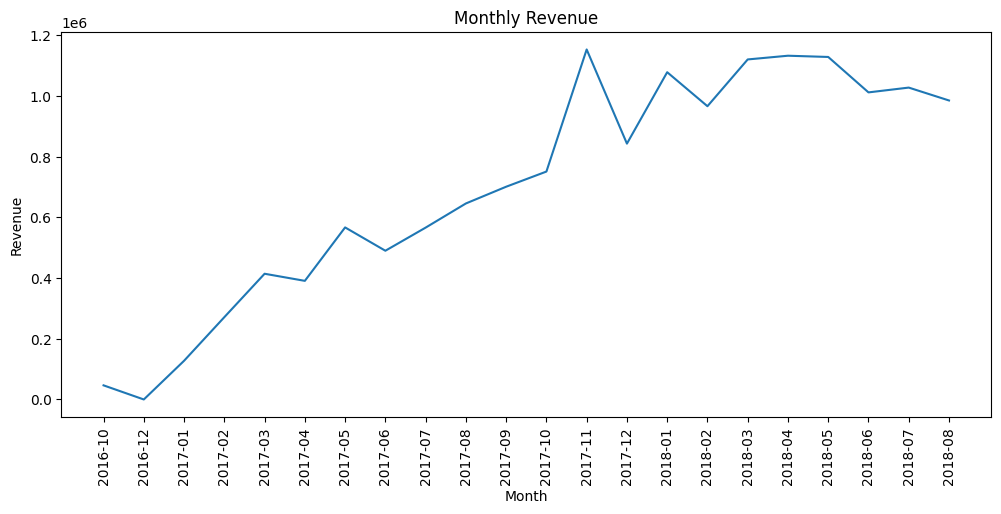

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(monthly["month"], monthly["revenue"])
plt.xticks(rotation=90)
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.title("Monthly Revenue")
plt.show()

### Вывод по динамике продаж

В течение основной части рассматриваемого периода наблюдается рост
ежемесячной выручки и количества заказов.

При этом динамика неоднородна по месяцам, поэтому отдельные изменения
могут быть связаны как с ростом marketplace, так и с сезонностью спроса.

## 6. Повторные покупки

Для оценки повторного поведения клиентов использую `customer_unique_id`,
так как `customer_id` в Olist относится к конкретному заказу и не подходит
для отслеживания одного клиента между покупками.

In [23]:
query = """
SELECT
    c.customer_unique_id,
    COUNT(DISTINCT o.order_id) AS orders_count
FROM customers c
JOIN orders o
    ON c.customer_id = o.customer_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_unique_id;
"""

customer_orders = pd.read_sql(query, conn)

customer_orders.head()

,customer_unique_id,orders_count
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0000f46a3911fa3c0805444483337064,1
3,0000f6ccb0745a6a4b88665a16c9f078,1
4,0004aac84e0df4da2b147fca70cf8255,1


In [24]:
customer_orders["orders_count"].value_counts().sort_index()

,count
orders_count,
1,90557
2,2573
3,181
4,28
5,9
6,5
7,3
9,1
15,1


In [25]:
repeat_rate = (
    (customer_orders["orders_count"] > 1).mean() * 100
)

round(repeat_rate, 2)

np.float64(3.0)

### Вывод по повторным покупкам

Около 3% клиентов совершили более одного доставленного заказа. Большинство пользователей совершили только одну покупку.

Это показывает низкую долю повторных заказов и делает удержание клиентов потенциальной зоной роста.

## 7. Когортный анализ retention

Клиенты объединяются в когорты по месяцу первой покупки.

Для каждой когорты рассчитывается доля пользователей,
которые совершили повторную покупку через 1, 2, 3 и более месяцев.

In [26]:
query = """
WITH customer_orders AS (
    SELECT
        c.customer_unique_id,
        o.order_id,
        o.order_purchase_timestamp
    FROM customers c
    JOIN orders o
        ON c.customer_id = o.customer_id
    WHERE o.order_status = 'delivered'
)

SELECT
    customer_unique_id,
    MIN(order_purchase_timestamp) AS first_order_date
FROM customer_orders
GROUP BY customer_unique_id;
"""

first_orders = pd.read_sql(query, conn)

first_orders.head()

,customer_unique_id,first_order_date
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42


In [27]:
query = """
WITH customer_orders AS (
    SELECT
        c.customer_unique_id,
        o.order_id,
        o.order_purchase_timestamp
    FROM customers c
    JOIN orders o
        ON c.customer_id = o.customer_id
    WHERE o.order_status = 'delivered'
),

first_orders AS (
    SELECT
        customer_unique_id,
        MIN(order_purchase_timestamp) AS first_order_date
    FROM customer_orders
    GROUP BY customer_unique_id
)

SELECT
    customer_unique_id,
    SUBSTR(first_order_date, 1, 7) AS cohort_month
FROM first_orders;
"""

cohorts = pd.read_sql(query, conn)

cohorts.head()

,customer_unique_id,cohort_month
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05
2,0000f46a3911fa3c0805444483337064,2017-03
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10
4,0004aac84e0df4da2b147fca70cf8255,2017-11


In [28]:
query = """
WITH customer_orders AS (
    SELECT
        c.customer_unique_id,
        o.order_id,
        o.order_purchase_timestamp,
        SUBSTR(o.order_purchase_timestamp, 1, 7) AS order_month
    FROM customers c
    JOIN orders o
        ON c.customer_id = o.customer_id
    WHERE o.order_status = 'delivered'
),

first_orders AS (
    SELECT
        customer_unique_id,
        MIN(order_purchase_timestamp) AS first_order_date
    FROM customer_orders
    GROUP BY customer_unique_id
),

orders_with_cohort AS (
    SELECT
        co.customer_unique_id,
        co.order_id,
        co.order_month,
        SUBSTR(fo.first_order_date, 1, 7) AS cohort_month,

        (
            (CAST(SUBSTR(co.order_month, 1, 4) AS INTEGER) -
             CAST(SUBSTR(fo.first_order_date, 1, 4) AS INTEGER)) * 12
            +
            (CAST(SUBSTR(co.order_month, 6, 2) AS INTEGER) -
             CAST(SUBSTR(fo.first_order_date, 6, 2) AS INTEGER))
        ) AS month_number

    FROM customer_orders co
    JOIN first_orders fo
        ON co.customer_unique_id = fo.customer_unique_id
)

SELECT
    cohort_month,
    month_number,
    COUNT(DISTINCT customer_unique_id) AS customers
FROM orders_with_cohort
GROUP BY cohort_month, month_number
ORDER BY cohort_month, month_number;
"""

retention_raw = pd.read_sql(query, conn)

retention_raw.head(20)

,cohort_month,month_number,customers
0,2016-09,0,1
1,2016-10,0,262
2,2016-10,6,1
3,2016-10,9,1
4,2016-10,11,1
5,2016-10,13,1
6,2016-10,15,1
7,2016-10,17,1
8,2016-10,19,2
9,2016-10,20,2


In [29]:
retention_matrix = retention_raw.pivot(
    index="cohort_month",
    columns="month_number",
    values="customers"
)

retention_matrix.head()

month_number,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,262.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0,NaN,1.0,NaN,1.0,NaN,1.0,NaN,1.0,2.0,2.0
2016-12,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,717.0,2.0,2.0,1.0,3.0,1.0,3.0,1.0,1.0,NaN,3.0,1.0,5.0,3.0,1.0,1.0,2.0,3.0,1.0,NaN
2017-02,1628.0,3.0,5.0,2.0,7.0,2.0,4.0,3.0,2.0,3.0,2.0,5.0,2.0,3.0,2.0,1.0,1.0,3.0,NaN,NaN


In [30]:
retention_rate = retention_matrix.div(
    retention_matrix[0],
    axis=0
) * 100

retention_rate = retention_rate.round(1)

retention_rate.head()

month_number,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,100.0,NaN,NaN,NaN,NaN,NaN,0.4,NaN,NaN,0.4,NaN,0.4,NaN,0.4,NaN,0.4,NaN,0.4,0.8,0.8
2016-12,100.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,100.0,0.3,0.3,0.1,0.4,0.1,0.4,0.1,0.1,NaN,0.4,0.1,0.7,0.4,0.1,0.1,0.3,0.4,0.1,NaN
2017-02,100.0,0.2,0.3,0.1,0.4,0.1,0.2,0.2,0.1,0.2,0.1,0.3,0.1,0.2,0.1,0.1,0.1,0.2,NaN,NaN


### Интерпретация когортной матрицы

После преобразования данных в когортную матрицу часть значений остаётся пустой.

`NaN` означает, что для соответствующей пары «когорта — месяц»
в исходных агрегированных данных отсутствует наблюдение. Для поздних когорт
часть периодов также выходит за пределы доступного временного диапазона.

Для итоговой визуализации рассматриваются первые 6 месяцев после первой
покупки. Месяц 0 исключён, поскольку в нём retention по определению равен 100%.

In [32]:
retention_plot = retention_rate.loc[
    "2017-01":"2018-04",
    1:6
]

retention_plot

month_number,1,2,3,4,5,6
cohort_month,,,,,,
2017-01,0.3,0.3,0.1,0.4,0.1,0.4
2017-02,0.2,0.3,0.1,0.4,0.1,0.2
2017-03,0.4,0.4,0.4,0.4,0.2,0.2
2017-04,0.6,0.2,0.2,0.3,0.3,0.4
2017-05,0.5,0.5,0.3,0.3,0.3,0.4
2017-06,0.5,0.4,0.4,0.3,0.4,0.4
2017-07,0.5,0.3,0.2,0.3,0.2,0.3
2017-08,0.7,0.3,0.3,0.3,0.5,0.3
2017-09,0.7,0.5,0.3,0.4,0.2,0.2


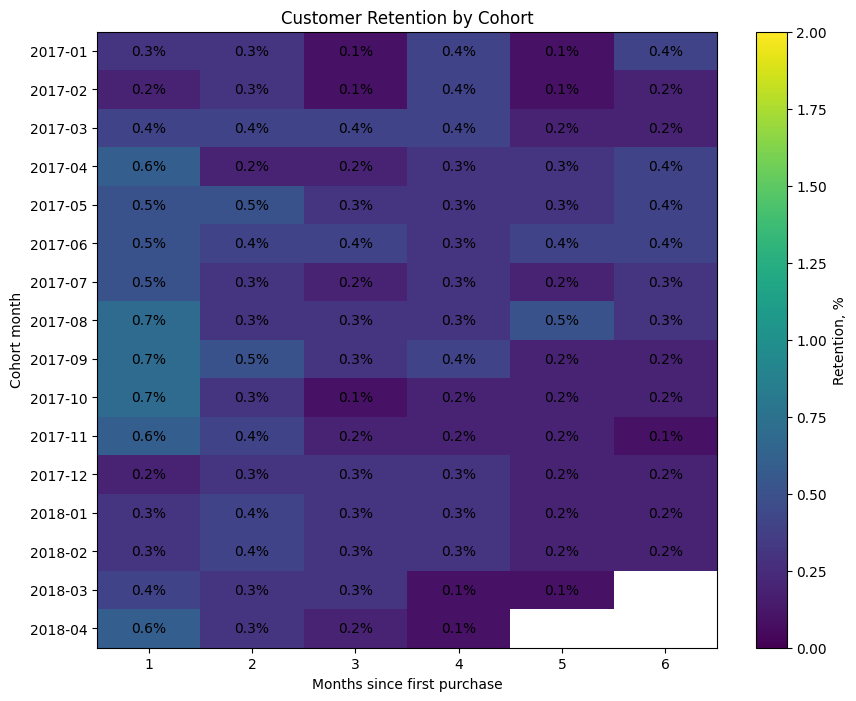

In [34]:
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    retention_plot,
    aspect="auto",
    vmin=0,
    vmax=2
)

ax.set_xticks(range(len(retention_plot.columns)))
ax.set_xticklabels(retention_plot.columns)

ax.set_yticks(range(len(retention_plot.index)))
ax.set_yticklabels(retention_plot.index)

for i in range(len(retention_plot.index)):
    for j in range(len(retention_plot.columns)):
        value = retention_plot.iloc[i, j]

        if pd.notna(value):
            ax.text(
                j,
                i,
                f"{value:.1f}%",
                ha="center",
                va="center"
            )

ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Cohort month")
ax.set_title("Customer Retention by Cohort")

plt.colorbar(im, label="Retention, %")
plt.show()

### Вывод по retention

Когортный анализ подтверждает низкий уровень повторных покупок:
в большинстве когорт ежемесячный retention после первой покупки
остаётся ниже 1%.

Результат согласуется с общей долей repeat customers около 3%.

## 8. Анализ товарных категорий

Сравниваю товарные категории по выручке, количеству заказов
и средней стоимости товара.

Для анализа используются только категории с достаточным количеством продаж,
чтобы единичные дорогие товары не искажали выводы.

In [35]:
query = """
SELECT
    p.product_category_name AS category,
    ROUND(SUM(oi.price), 2) AS revenue,
    COUNT(DISTINCT oi.order_id) AS orders
FROM order_items oi
JOIN products p
    ON oi.product_id = p.product_id
JOIN orders o
    ON oi.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND p.product_category_name IS NOT NULL
GROUP BY p.product_category_name
ORDER BY revenue DESC
LIMIT 10;
"""

top_categories = pd.read_sql(query, conn)

top_categories

,category,revenue,orders
0,beleza_saude,1233131.72,8647
1,relogios_presentes,1166176.98,5495
2,cama_mesa_banho,1023434.76,9272
3,esporte_lazer,954852.55,7530
4,informatica_acessorios,888724.61,6530
5,moveis_decoracao,711927.69,6307
6,utilidades_domesticas,615628.69,5743
7,cool_stuff,610204.10,3559
8,automotivo,578966.65,3810
9,brinquedos,471286.48,3804


In [36]:
query = """
SELECT
    p.product_category_name AS category,
    ROUND(AVG(oi.price), 2) AS avg_item_price,
    COUNT(*) AS items_sold
FROM order_items oi
JOIN products p
    ON oi.product_id = p.product_id
JOIN orders o
    ON oi.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND p.product_category_name IS NOT NULL
GROUP BY p.product_category_name
HAVING COUNT(*) >= 100
ORDER BY avg_item_price DESC
LIMIT 10;
"""

category_price = pd.read_sql(query, conn)

category_price

,category,avg_item_price,items_sold
0,pcs,1098.92,199
1,eletrodomesticos_2,467.33,231
2,agro_industria_e_comercio,342.55,206
3,instrumentos_musicais,283.13,651
4,eletroportateis,277.74,658
5,telefonia_fixa,216.92,255
6,construcao_ferramentas_seguranca,211.88,183
7,relogios_presentes,199.04,5859
8,moveis_quarto,184.97,103
9,climatizacao,184.51,289


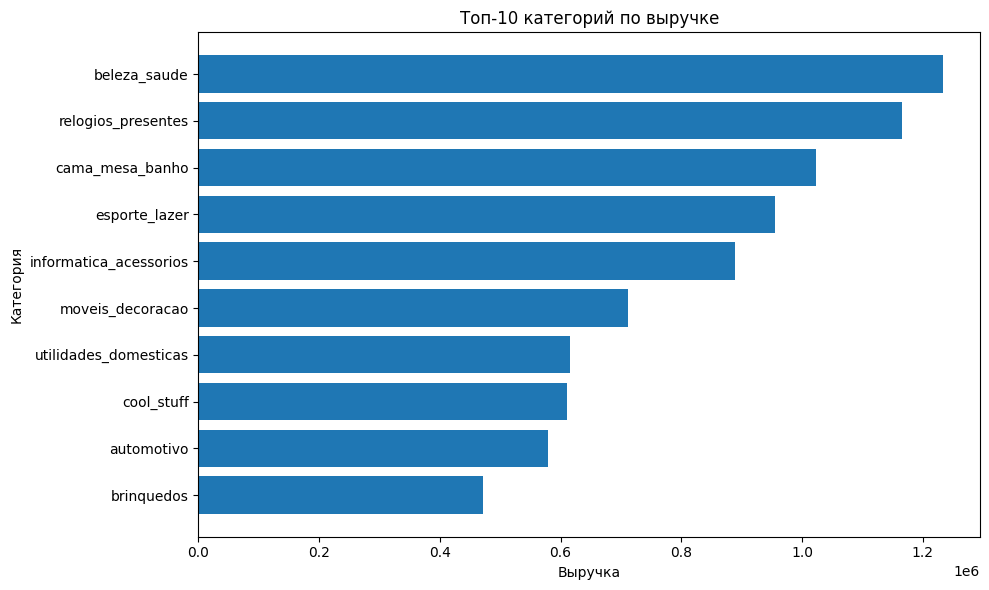

In [37]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_categories["category"][::-1],
    top_categories["revenue"][::-1]
)

plt.xlabel("Выручка")
plt.ylabel("Категория")
plt.title("Топ-10 категорий по выручке")

plt.tight_layout()
plt.show()

### Вывод по товарным категориям

Наибольшую выручку формируют категории `beleza_saude`,
`relogios_presentes` и `cama_mesa_banho`.

При этом категории с самой высокой средней стоимостью товара
не обязательно являются лидерами по общей выручке:
на итоговый результат влияет также объём продаж.

## 9. Анализ доставки

Качество доставки является важной частью пользовательского опыта
e-commerce продукта.

Рассчитываю средний фактический срок доставки, ожидаемый срок
и долю заказов, доставленных позже обещанной даты.

In [38]:
query = """
SELECT
    ROUND(
        AVG(
            julianday(order_delivered_customer_date)
            - julianday(order_purchase_timestamp)
        ),
        1
    ) AS avg_delivery_days,

    ROUND(
        AVG(
            julianday(order_estimated_delivery_date)
            - julianday(order_purchase_timestamp)
        ),
        1
    ) AS avg_estimated_days,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN date(order_delivered_customer_date)
                     > date(order_estimated_delivery_date)
                THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS late_delivery_rate

FROM orders
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL
  AND order_estimated_delivery_date IS NOT NULL;
"""

delivery_metrics = pd.read_sql(query, conn)

delivery_metrics

,avg_delivery_days,avg_estimated_days,late_delivery_rate
0,12.6,23.7,6.77


### Вывод по доставке

Средний фактический срок доставки составляет 12.6 дня,
при среднем ожидаемом сроке 23.7 дня.

Около 6.77% доставленных заказов были получены позже обещанной даты.

## 10. Доставка и пользовательские оценки

Чтобы проверить возможную связь между качеством доставки
и удовлетворённостью покупателей, разделяю заказы по величине задержки
и сравниваю средний `review_score`.

In [39]:
query = """
SELECT
    CASE
        WHEN julianday(o.order_delivered_customer_date)
             <= julianday(o.order_estimated_delivery_date)
        THEN 'В срок или раньше'

        WHEN julianday(o.order_delivered_customer_date)
             - julianday(o.order_estimated_delivery_date) <= 3
        THEN 'Опоздание 1–3 дня'

        WHEN julianday(o.order_delivered_customer_date)
             - julianday(o.order_estimated_delivery_date) <= 7
        THEN 'Опоздание 4–7 дней'

        ELSE 'Опоздание 8+ дней'
    END AS delivery_group,

    COUNT(DISTINCT o.order_id) AS orders,

    ROUND(AVG(r.review_score), 2) AS avg_review_score

FROM orders o

JOIN reviews r
    ON o.order_id = r.order_id

WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_estimated_delivery_date IS NOT NULL

GROUP BY delivery_group

ORDER BY
    CASE delivery_group
        WHEN 'В срок или раньше' THEN 1
        WHEN 'Опоздание 1–3 дня' THEN 2
        WHEN 'Опоздание 4–7 дней' THEN 3
        WHEN 'Опоздание 8+ дней' THEN 4
    END;
"""

delivery_reviews = pd.read_sql(query, conn)

delivery_reviews

,delivery_group,orders,avg_review_score
0,В срок или раньше,88163,4.29
1,Опоздание 1–3 дня,2636,3.77
2,Опоздание 4–7 дней,1773,2.32
3,Опоздание 8+ дней,3252,1.73


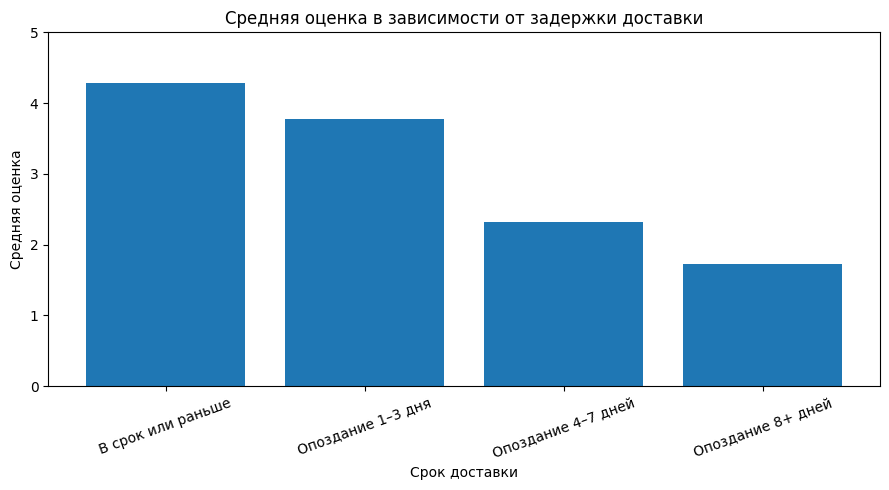

In [40]:
plt.figure(figsize=(9, 5))

plt.bar(
    delivery_reviews["delivery_group"],
    delivery_reviews["avg_review_score"]
)

plt.xlabel("Срок доставки")
plt.ylabel("Средняя оценка")
plt.title("Средняя оценка в зависимости от задержки доставки")

plt.xticks(rotation=20)
plt.ylim(0, 5)

plt.tight_layout()
plt.show()

### Вывод по влиянию задержек на пользовательские оценки

Средняя оценка заметно снижается с увеличением задержки доставки.

Для заказов, доставленных вовремя или раньше срока,
средняя оценка составляет 4.29.

При задержке 1–3 дня она снижается до 3.77,
при задержке 4–7 дней — до 2.32,
а при задержке более 8 дней — до 1.73.

Это показывает выраженную связь между соблюдением сроков доставки
и уровнем пользовательской оценки.

### Распределение пользовательских оценок

Дополнительно анализирую общее распределение review score,
чтобы понять структуру клиентской обратной связи.

In [41]:
query = """
SELECT
    review_score,
    COUNT(*) AS reviews_count
FROM reviews
GROUP BY review_score
ORDER BY review_score;
"""

review_distribution = pd.read_sql(query, conn)

review_distribution

,review_score,reviews_count
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328


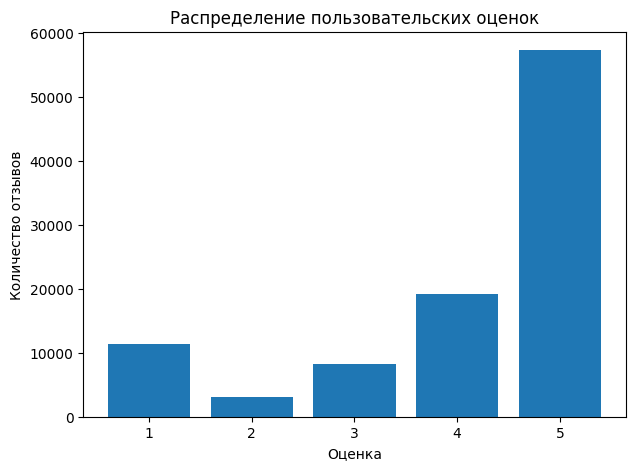

In [42]:
plt.figure(figsize=(7, 5))

plt.bar(
    review_distribution["review_score"],
    review_distribution["reviews_count"]
)

plt.xlabel("Оценка")
plt.ylabel("Количество отзывов")
plt.title("Распределение пользовательских оценок")

plt.show()

In [43]:
query = """
SELECT
    COUNT(DISTINCT o.order_id) AS delivered_orders,

    COUNT(DISTINCT c.customer_unique_id) AS customers,

    ROUND(SUM(p.payment_value), 2) AS revenue,

    ROUND(
        SUM(p.payment_value)
        / COUNT(DISTINCT o.order_id),
        2
    ) AS aov

FROM orders o

JOIN customers c
    ON o.customer_id = c.customer_id

JOIN payments p
    ON o.order_id = p.order_id

WHERE o.order_status = 'delivered';
"""

summary_metrics = pd.read_sql(query, conn)

summary_metrics

,delivered_orders,customers,revenue,aov
0,96477,93357,15422461.77,159.86


In [44]:
summary_metrics["repeat_purchase_rate"] = round(repeat_rate, 2)

summary_metrics

,delivered_orders,customers,revenue,aov,repeat_purchase_rate
0,96477,93357,15422461.77,159.86,3.0


# Итоги

В проекте были проанализированы продажи, поведение клиентов,
товарные категории, retention, доставка и пользовательские оценки.

## Основные выводы

- Для доставленных заказов выручка составляет около 15.4 млн,
  средний чек — 159.86.
- Только около 3% клиентов совершают повторные покупки.
- Когортный retention после первой покупки остаётся очень низким.
- Наибольшую выручку формирует ограниченная группа товарных категорий.
- Средний фактический срок доставки составляет 12.6 дня,
  а доля поздних доставок — 6.77%.
- С увеличением задержки средняя оценка клиента заметно снижается:
  с 4.29 для своевременных доставок до 1.73 при задержке более 8 дней.

## Возможные направления улучшения

- развитие механик повторных покупок и retention;
- персональные предложения после первой покупки;
- отдельная работа с наиболее значимыми товарными категориями;
- снижение количества поздних доставок;
- мониторинг пользовательских оценок как индикатора качества клиентского опыта.
